# What is the most optimal skill to learn for Data Analysts?

## Approach
1. Group skills to determine median salary and likelihood of being in posting
2. Visualize median salary vs percent skill demand
3. Determine if certain technologies are more prevalent

In [1]:

import ast
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt
from adjustText import adjust_text
import seaborn as sns

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x:ast.literal_eval(x) if pd.notna(x) else x)


In [2]:
df_DA_IN = df[(df['job_title'] == 'Data Analyst') & (df['job_country']=='India')].copy()
df_DA_IN.sample(5)

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
66957,Data Analyst,Data Analyst,Anywhere,via LinkedIn,Full-time,True,India,2023-04-11 06:53:21,False,False,India,NaN,NaN,NaN,CoreInsightsAI,NaN,NaN
120475,Data Analyst,Data Analyst,India,via BeBee India,Full-time,False,India,2023-05-24 08:09:07,True,False,India,NaN,NaN,NaN,Structured Learning Assistance Consultants Ind...,"[vba, sql, python, r, excel, power bi, tableau...","{'analyst_tools': ['excel', 'power bi', 'table..."
509355,Data Analyst,Data Analyst,Anywhere,via LinkedIn,Full-time,True,India,2023-11-29 11:11:16,True,False,India,NaN,NaN,NaN,Idyllic Services Pvt. Ltd.,"[python, sql, pyspark]","{'libraries': ['pyspark'], 'programming': ['py..."
251289,Data Analyst,Data Analyst,India,via SimplyHired,Full-time,False,India,2023-02-09 07:28:20,False,False,India,NaN,NaN,NaN,Talent Zone Consultants,"[sql, python]","{'programming': ['sql', 'python']}"
418796,Data Analyst,Data Analyst,"Gurugram, Haryana, India",via LinkedIn,Full-time,False,India,2023-07-16 16:14:01,True,False,India,NaN,NaN,NaN,EXL,NaN,NaN


In [7]:
df_DA_IN = df_DA_IN.dropna(subset=['salary_year_avg'])
df_DA_IN_exploded = df_DA_IN.explode('job_skills')

df_DA_IN_exploded[['salary_year_avg','job_skills']].head(10)


,salary_year_avg,job_skills
56450,57500.0,tableau
56450,57500.0,power bi
60528,105000.0,r
60528,105000.0,python
60528,105000.0,spss
168402,650000.0,NaN
263296,102500.0,c
263296,102500.0,sql
263296,102500.0,bigquery
263296,102500.0,github


In [34]:
df_DA_skills = df_DA_IN_exploded.groupby('job_skills')['salary_year_avg'].agg(
    ['count','median']
).sort_values(by='count',ascending=False)

df_DA_skills = df_DA_skills.rename(columns = {'count' : 'skill_count', 'median' : 'median_salary'})

DA_job_count = len(df_DA_IN)

df_DA_skills['skill_percent'] = df_DA_skills['skill_count'] / DA_job_count * 100

min_skill_percent_to_plot = 7

df_DA_skills_high_demand = df_DA_skills[df_DA_skills['skill_percent'] > min_skill_percent_to_plot]

df_DA_skills_high_demand

,skill_count,median_salary,skill_percent
job_skills,,,
sql,8,111175.0,53.333333
python,6,111175.0,40.000000
tableau,5,111175.0,33.333333
excel,5,111175.0,33.333333
r,4,111175.0,26.666667
powerpoint,4,111175.0,26.666667
power bi,3,111175.0,20.000000
spark,3,111175.0,20.000000
slack,2,106837.5,13.333333


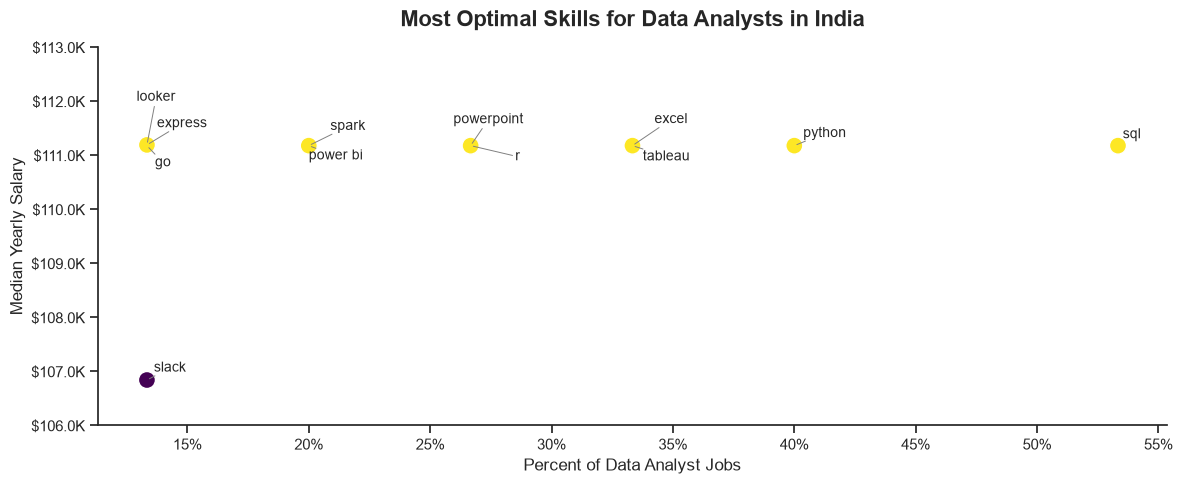

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from adjustText import adjust_text

sns.set_theme(style='ticks')

fig, ax = plt.subplots(figsize=(12, 5))

sns.scatterplot(
    data=df_DA_skills_high_demand,
    x='skill_percent',
    y='median_salary',
    hue='median_salary',
    palette='viridis',
    s=150,
    legend=False,
    ax=ax
)

texts = []

for i, txt in enumerate(df_DA_skills_high_demand.index):
    texts.append(
        ax.text(
            df_DA_skills_high_demand['skill_percent'].iloc[i],
            df_DA_skills_high_demand['median_salary'].iloc[i],
            txt,
            fontsize=10
        )
    )

ax.set_ylim(106000, 113000)


adjust_text(
    texts,
    x=df_DA_skills_high_demand['skill_percent'],
    y=df_DA_skills_high_demand['median_salary'],
    ax=ax,
    expand=(1.3, 1.8),
    force_text=(1, 1.0),
    arrowprops=dict(arrowstyle='-', color='gray', lw=0.7)
)

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda y, pos: f'${y/1000:.1f}K')
)

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f'{x:.0f}%')
)

ax.set_xlabel('Percent of Data Analyst Jobs', fontsize=12)
ax.set_ylabel('Median Yearly Salary', fontsize=12)
ax.set_title(
    'Most Optimal Skills for Data Analysts in India',
    fontsize=16,
    weight='bold',
    pad=15
)

sns.despine()
plt.tight_layout()
plt.show()

In [43]:
df['job_type_skills'].head(10)

0                                                  NaN
1    {'analyst_tools': ['power bi', 'tableau'], 'pr...
2    {'analyst_tools': ['dax'], 'cloud': ['azure'],...
3    {'cloud': ['aws'], 'libraries': ['tensorflow',...
4    {'cloud': ['oracle', 'aws'], 'other': ['ansibl...
5    {'cloud': ['gcp'], 'programming': ['python', '...
6    {'cloud': ['gcp', 'bigquery'], 'databases': ['...
7    {'cloud': ['gcp', 'azure', 'aws', 'bigquery', ...
8    {'analyst_tools': ['excel', 'powerpoint', 'pow...
9    {'analyst_tools': ['excel'], 'cloud': ['azure'...
Name: job_type_skills, dtype: str

In [44]:
df_technology = df['job_type_skills'].copy()

# remove duplicates
df_technology = df_technology.drop_duplicates()

# remove NaN values
df_technology = df_technology.dropna()

# combine all dictionaries into one
technology_dict = {}
for row in df_technology:
    row_dict = ast.literal_eval(row)  # convert string to dictionary
    for key, value in row_dict.items():
        if key in technology_dict:  # if key already exists in technology_dict, add value to existing value
            technology_dict[key] += value
        else:                       # if key does not exist in technology_dict, add key and value
            technology_dict[key] = value

# remove duplicates by converting values to set then back to list
for key, value in technology_dict.items():
    technology_dict[key] = list(set(value))

technology_dict

{'analyst_tools': ['qlik',
  'ms access',
  'ssrs',
  'sap',
  'datarobot',
  'powerpoint',
  'excel',
  'power bi',
  'sas',
  'sheets',
  'word',
  'esquisse',
  'visio',
  'sharepoint',
  'cognos',
  'splunk',
  'alteryx',
  'spss',
  'microstrategy',
  'nuix',
  'msaccess',
  'powerbi',
  'dax',
  'tableau',
  'looker',
  'outlook',
  'ssis',
  'spreadsheet'],
 'programming': ['mongo',
  'assembly',
  'typescript',
  'r',
  'no-sql',
  'julia',
  'visual basic',
  't-sql',
  'c++',
  'matlab',
  'rust',
  'kotlin',
  'java',
  'haskell',
  'sas',
  'apl',
  'css',
  'perl',
  'vb.net',
  'scala',
  'c#',
  'shell',
  'lisp',
  'php',
  'nosql',
  'ruby',
  'swift',
  'sql',
  'go',
  'bash',
  'mongodb',
  'golang',
  'erlang',
  'visualbasic',
  'cobol',
  'solidity',
  'f#',
  'pascal',
  'ocaml',
  'dart',
  'python',
  'powershell',
  'javascript',
  'fortran',
  'groovy',
  'vba',
  'lua',
  'objective-c',
  'html',
  'elixir',
  'sass',
  'c',
  'clojure',
  'delphi',
  'crys

In [45]:
df_technology = pd.DataFrame(list(technology_dict.items()), columns=['technology', 'skills'])

df_technology = df_technology.explode('skills')

df_technology

,technology,skills
0,analyst_tools,qlik
0,analyst_tools,ms access
0,analyst_tools,ssrs
0,analyst_tools,sap
0,analyst_tools,datarobot
...,...,...
9,sync,wire
9,sync,slack
9,sync,microsoft teams
9,sync,ringcentral


In [46]:
# merge df_DA_skills and df_technology
df_DA_skills_tech = df_DA_skills.merge(df_technology, left_on='job_skills', right_on='skills')

df_DA_skills_tech

,skill_count,median_salary,skill_percent,technology,skills
0,8,111175.0,53.333333,programming,sql
1,6,111175.0,40.000000,programming,python
2,5,111175.0,33.333333,analyst_tools,tableau
3,5,111175.0,33.333333,analyst_tools,excel
4,4,111175.0,26.666667,programming,r
5,4,111175.0,26.666667,analyst_tools,powerpoint
6,3,111175.0,20.000000,analyst_tools,power bi
7,3,111175.0,20.000000,libraries,spark
8,2,106837.5,13.333333,sync,slack
9,2,111188.5,13.333333,analyst_tools,looker


In [48]:
skill_limit = 7
df_DA_skills_tech_high_demand = df_DA_skills_tech[df_DA_skills_tech['skill_percent'] > skill_limit]

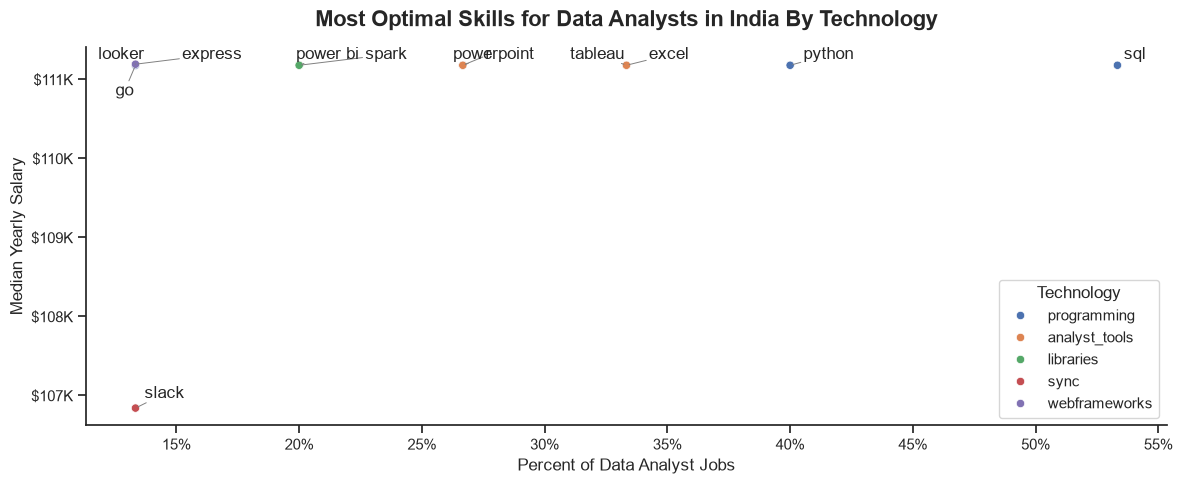

In [71]:
fig, ax = plt.subplots(figsize=(12, 5))

sns.scatterplot(
    data=df_DA_skills_tech_high_demand,
    x='skill_percent',
    y='median_salary',
    hue='technology'
)

sns.despine()
sns.set_theme(style='ticks')

# Prepare texts for adjustText
texts = []
for i, txt in enumerate(df_DA_skills_high_demand.index):
    texts.append(plt.text(df_DA_skills_high_demand['skill_percent'].iloc[i], df_DA_skills_high_demand['median_salary'].iloc[i], txt))

# Adjust text to avoid overlap
adjust_text(
    texts,
    x=df_DA_skills_high_demand['skill_percent'],
    y=df_DA_skills_high_demand['median_salary'],
    ax=ax,
    expand=(1.3, 1.8),
    force_text=(1, 1.0),
    arrowprops=dict(arrowstyle='-', color='gray', lw=0.7)
)

# Set axis labels, title, and legend
plt.xlabel('Percent of Data Analyst Jobs')
plt.ylabel('Median Yearly Salary')
ax.set_title(
    'Most Optimal Skills for Data Analysts in India By Technology',
    fontsize=16,
    weight='bold',
    pad=15
)
plt.legend(title='Technology')

from matplotlib.ticker import PercentFormatter
ax = plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos: f'${int(y/1000)}K'))
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))

# Adjust layout and display plot 
plt.tight_layout()
plt.show()